# Fixed vs dynamic gradient descent

In [22]:
import numpy as np
import matplotlib.pyplot as plt

In [23]:
# Gradient descent in 1D

def f_fx(x):
    return 3*x**2-3*x +4

# Derivative function

def f_dx(x):
    return 6*x -3


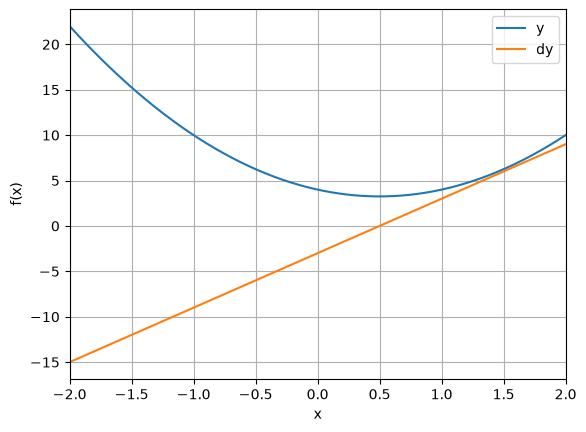

In [24]:
# Plot the function and its derivative

x = np.linspace(-2,2,2001)

# Create plot

plt.plot(x,f_fx(x))
plt.plot(x,f_dx(x))

plt.xlim(x[[0,-1]])

plt.grid()

plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend(['y','dy'])

plt.show()

## Gradient descent using a fixed learning rate

Starting learning from [1.66]


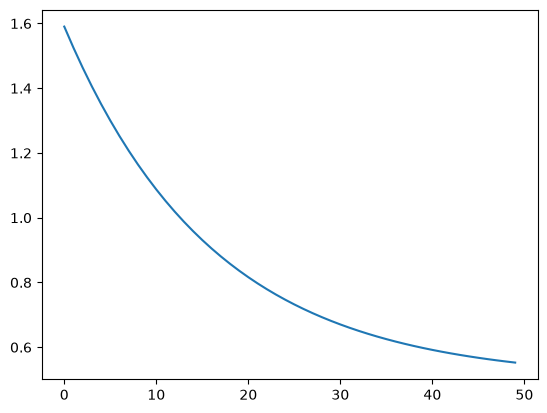

In [25]:
# Select random starting point

localmin = np.random.choice(x,1)
initialValue = localmin[:]

print(f"Starting learning from {localmin}")

# Set learning parameteres

learningRate = 0.01
trainingEpochs = 50

# Run through training and store results

modelparamsFixed =np.zeros((trainingEpochs,3))

for i in range(trainingEpochs):
    # Compute derivative
    grad = f_dx(localmin)

    # Not adapting learning rate
    lr = learningRate

    # Update localmin according to gd algorithm
    localmin = localmin - lr*grad

    # Store result
    modelparamsFixed[i,:] = localmin[0],grad[0],lr

plt.plot(modelparamsFixed[:, 0])
plt.plot()
plt.show()


## Gradient descent using a gradient-based learning rate

Starting learning from [-1.99]


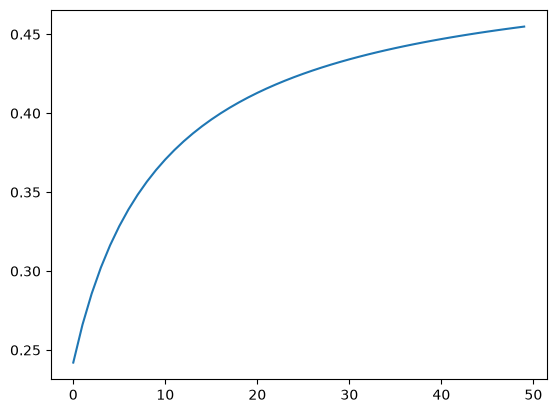

In [26]:
# Select random starting point

localmin = np.random.choice(x,1)
initialValue = localmin[:]

print(f"Starting learning from {localmin}")

# Set learning parameteres

learningRate = 0.01
trainingEpochs = 50

# Run through training and store results

modelparamsGrad =np.zeros((trainingEpochs,3))

for i in range(trainingEpochs):
    # Compute derivative
    grad = f_dx(localmin)

    # Adapt the learning rate according to the gradient
    lr = learningRate*np.abs(grad)

    # Update localmin according to gd algorithm
    localmin = localmin - lr*grad    

    # Store result
    modelparamsGrad[i,:] = localmin[0],grad[0],lr[0]

plt.plot(modelparamsGrad[:, 0])
plt.plot()
plt.show()


## GD using a time-based learning rate

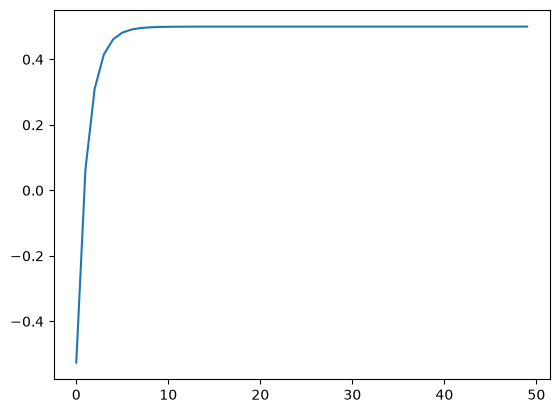

In [27]:

# Set learning parameteres

learningRate = 0.1
localmin= initialValue

# Run through training and store results

modelparamsTime =np.zeros((trainingEpochs,3))

for i in range(trainingEpochs):
    # Compute derivative
    grad = f_dx(localmin)

    # Adapt the learning rate according to the gradient
    lr = learningRate*(1-(i+1)/trainingEpochs)

    # Update localmin according to gd algorithm
    localmin = localmin - lr*grad    
    
    # Store result
    modelparamsTime[i,:] = localmin[0],grad[0],lr

plt.plot(modelparamsTime[:, 0])
plt.plot()
plt.show()


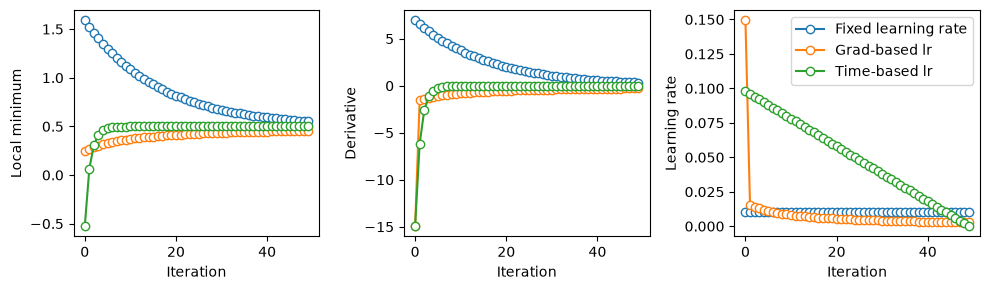

In [28]:
# Plot every result

fix, ax = plt.subplots(1,3,figsize=(10,3))

for i in range(3):
    ax[i].plot(modelparamsFixed[:,i],'o-', markerfacecolor='w')
    ax[i].plot(modelparamsGrad[:,i],'o-', markerfacecolor='w')
    ax[i].plot(modelparamsTime[:,i],'o-', markerfacecolor='w')
    ax[i].set_xlabel('Iteration')

ax[0].set_ylabel('Local minimum')
ax[1].set_ylabel('Derivative')
ax[2].set_ylabel('Learning rate')

ax[2].legend(['Fixed learning rate','Grad-based lr','Time-based lr'])

plt.tight_layout()
plt.show()
    

The tests have proven the time-based learning rate not only be the most precise but also got to the minimum value with less iterations

## Aditional explorations